# Stage 9 — Edge AI optimization (ONNX + quantization)

Run `python scripts/benchmark_onnx.py` first. It writes `reports/stage9_onnx_benchmark.json`, which this notebook
displays. Nothing here is computed from assumptions: every number is measured on the machine that ran the script.

Check the warning in the report: if it says *synthetic* or *random-init*, the numbers are a smoke test only.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
report_path = PROJECT_ROOT / "reports" / "stage9_onnx_benchmark.json"
if not report_path.exists():
    raise FileNotFoundError("Run `python scripts/benchmark_onnx.py` first.")
report = json.loads(report_path.read_text(encoding="utf-8"))
meta, results = report["meta"], pd.DataFrame(report["results"]).set_index("variant")
if meta["synthetic_data_smoke_test_only"] or not meta["resnet_pretrained_weights"]:
    print("WARNING: SMOKE TEST ONLY (synthetic data and/or random weights). Do not quote these numbers.")
meta

{'synthetic_data_smoke_test_only': False,
 'resnet_pretrained_weights': True,
 'parameters': 11176512,
 'device': 'CPU',
 'cpu': 'Intel64 Family 6 Model 140 Stepping 2, GenuineIntel',
 'os': 'Windows-10-10.0.22631-SP0',
 'python': '3.11.3',
 'torch': '2.14.0+cpu',
 'onnxruntime': '1.30.0',
 'test_images': 83,
 'calibration_images': 50,
 'latency_runs': 50}

In [2]:
results

,size_mb,latency_mean_ms,latency_p50_ms,latency_p95_ms,peak_memory_mb,cosine_mean,cosine_min,max_abs_diff,roc_auc_test,decision_agreement_vs_pytorch,accuracy_at_threshold,size_vs_pytorch,latency_vs_pytorch
variant,,,,,,,,,,,,,
PyTorch fp32,42.71,52.75,51.54,60.01,368.1,1.00000,1.00000,0.00000,0.9698,1.0000,0.9398,1.000,1.000
ONNX fp32,42.63,35.72,32.29,48.56,164.6,1.00000,1.00000,0.00001,0.9698,1.0000,0.9398,0.998,0.677
ONNX int8 (static),10.77,15.01,14.89,17.74,71.1,0.99900,0.99797,0.52380,0.9913,0.9759,0.9639,0.252,0.285
ONNX int8 (dynamic),10.71,624.78,759.24,869.99,78.4,0.99741,0.99457,0.68646,0.9079,0.9157,0.9277,0.251,11.844


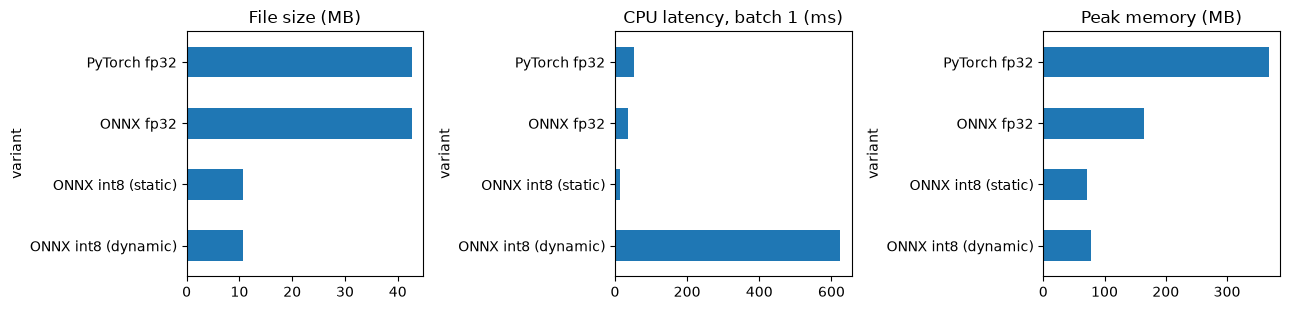

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, title in zip(axes, ("size_mb", "latency_mean_ms", "peak_memory_mb"),
                          ("File size (MB)", "CPU latency, batch 1 (ms)", "Peak memory (MB)")):
    results[col].plot.barh(ax=ax, title=title); ax.invert_yaxis()
plt.tight_layout(); plt.show()

## How to read it
* **Size** shrinks about 4x with int8 weights.
* **Latency** depends on your CPU. int8 can be slower than fp32 on CPUs without int8 acceleration; that is a legitimate finding.
* **cosine_mean / max_abs_diff** show how far quantization moved the features.
* **roc_auc_test / decision_agreement_vs_pytorch** show whether the *task result* changed. The OCSVM head was fitted on
  fp32 features, so this is the realistic "swap the backbone, keep the head" scenario.
* Dynamic quantization is designed for Linear/MatMul layers, so it is expected to help little for a CNN. It is here to show that.

Write your own conclusion: which variant would you ship for a CPU-only camera box, and why?